# Phase 5: Market Basket Analysis (Department-Level)
**Integrated Retail Analytics for Store Optimization - Capstone**

**Objective:** Infer product/department associations without individual customer transaction data, and propose cross-selling / store-layout strategies from the inferred associations.

**The adaptation:** classic market basket analysis needs a receipt - "customer X bought bread, butter, milk in one trip." We don't have that here. Instead, we treat **each store-week as one "basket,"** and ask a different but related question: *which departments tend to have an unusually strong sales week at the same store, in the same week?* If Dept A and Dept B consistently "boom" together, that's a signal they're likely driven by the same shoppers/trips or the same seasonal demand - useful for cross-selling and store layout, even without seeing individual receipts.

In [5]:
# from google.colab import drive
# drive.mount('/content/drive')

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

## 1. Define a "boom week" for each department
Each department has its own normal sales range (Dept 92 might normally do $50k/week, Dept 3 might do $2k/week) - so "unusually strong" is defined **relative to that department's own top 25% of weeks**, not a single dollar cutoff across all departments.

In [7]:
df = pd.read_csv(r"/content/drive/MyDrive/Integrated Retail Analytics for Store Optimization/Capston Anomaly Detection/Anomaly tagged data output/anomaly_tagged_data.csv", parse_dates=['Date'])

dept_thresh = df.groupby('Dept')['Weekly_Sales'].quantile(0.75)
df['Dept_Thresh'] = df['Dept'].map(dept_thresh)
df['Boom'] = (df['Weekly_Sales'] > df['Dept_Thresh']).astype(int)

print(f"Boom weeks flagged: {df['Boom'].sum()} rows ({df['Boom'].mean():.1%} of all rows, as expected for a 75th-percentile cutoff)")

Boom weeks flagged: 105338 rows (25.0% of all rows, as expected for a 75th-percentile cutoff)


## 2. Build the "basket" table
One row per Store-Week (a "basket"), one column per Department, `True` if that department had a boom week at that store that week.

In [8]:
basket = df.pivot_table(index=['Store','Date'], columns='Dept', values='Boom', fill_value=0).astype(bool)
print(f"Baskets (store-weeks): {basket.shape[0]}  |  Departments (items): {basket.shape[1]}")
basket.iloc[:5, :8]

Baskets (store-weeks): 6435  |  Departments (items): 81


Dept                  1      2      3     4      5      6      7      8
Store Date                                                             
1     2010-02-05   True  False   True  True   True  False  False   True
      2010-02-12   True  False  False  True   True   True  False  False
      2010-02-19   True  False  False  True  False  False  False   True
      2010-02-26  False  False  False  True  False  False  False  False
      2010-03-05  False  False  False  True  False  False  False   True

## 3. Mine frequent department pairs and association rules
- **Support** - how often this pair of departments booms together, out of all baskets
- **Confidence** - given Dept A boomed, how often Dept B also boomed
- **Lift** - how much more likely they boom together than pure chance would predict (lift > 1 = real association, lift = 1 = no relationship, lift < 1 = they tend to avoid booming together)

In [9]:
frequent_pairs = apriori(basket, min_support=0.15, use_colnames=True, max_len=2)
rules = association_rules(frequent_pairs, metric='lift', min_threshold=1.2)

# de-duplicate: A->B and B->A are the same underlying pair, keep one representative row
rules['pair_key'] = rules.apply(lambda r: tuple(sorted([tuple(r['antecedents']), tuple(r['consequents'])])), axis=1)
rules_unique = rules.drop_duplicates(subset='pair_key').sort_values('lift', ascending=False)

print(f"Total association rules found: {len(rules)}  |  Unique department pairs: {len(rules_unique)}")
rules_unique[['antecedents','consequents','support','confidence','lift']].head(15)

Total association rules found: 796  |  Unique department pairs: 398


,antecedents,consequents,support,confidence,lift
530,(24),(33),0.181818,0.865385,4.131120
742,(90),(92),0.233411,0.933499,3.733416
560,(34),(30),0.158819,0.767267,3.731946
740,(90),(91),0.231235,0.924798,3.698617
776,(93),(94),0.185392,0.807172,3.655279
778,(93),(95),0.209169,0.910690,3.642194
780,(97),(93),0.204040,0.836306,3.641155
354,(22),(14),0.195183,0.906205,3.624256
790,(97),(95),0.220979,0.905732,3.622367
754,(91),(92),0.225019,0.899938,3.599192


## 4. Visualize the strongest department associations

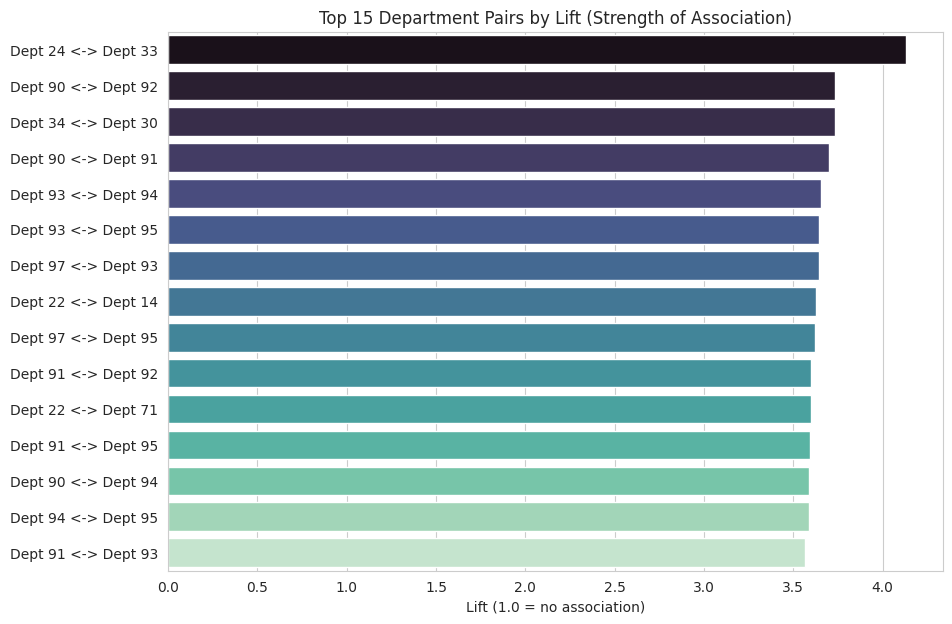

In [10]:
top15 = rules_unique.head(15).copy()
top15['pair_label'] = top15.apply(lambda r: f"Dept {list(r['antecedents'])[0]} <-> Dept {list(r['consequents'])[0]}", axis=1)

plt.figure(figsize=(10,7))
sns.barplot(data=top15, y='pair_label', x='lift', palette='mako')
plt.title('Top 15 Department Pairs by Lift (Strength of Association)')
plt.xlabel('Lift (1.0 = no association)')
plt.ylabel('')
plt.show()

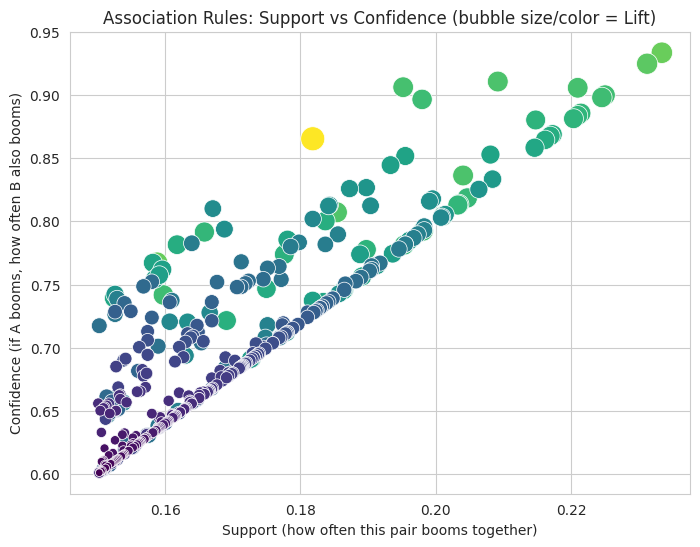

In [11]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=rules_unique, x='support', y='confidence', size='lift', hue='lift',
                 palette='viridis', sizes=(30,300), legend=False)
plt.title('Association Rules: Support vs Confidence (bubble size/color = Lift)')
plt.xlabel('Support (how often this pair booms together)')
plt.ylabel('Confidence (if A booms, how often B also booms)')
plt.show()

**Insight:** a handful of department pairs stand out with lift around 3.5-4x - meaning these departments boom together roughly 3.5-4 times more often than if their sales were completely independent. This is a strong signal, not noise: something (a shared shopper trip, a shared seasonal driver, or a shared regional promotion) is genuinely linking these departments' demand.

## 5. Complementary check - overall department correlation
Association rules only look at "boom" weeks (top 25%). As a sanity check, a plain correlation of raw weekly sales (not just boom weeks) between the most strongly linked departments confirms the same relationship shows up in the full sales pattern, not just at extreme weeks.

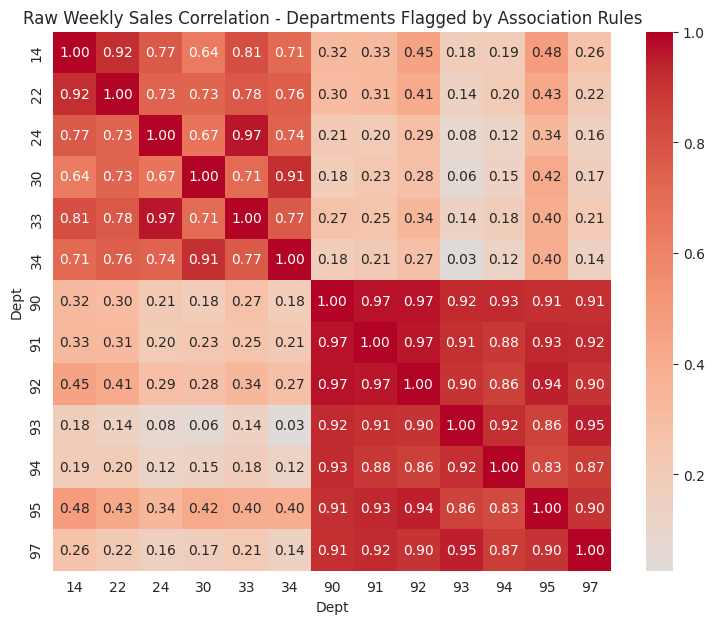

In [12]:
top_depts = set()
for _, r in rules_unique.head(8).iterrows():
    top_depts.update(list(r['antecedents']) + list(r['consequents']))
top_depts = sorted(top_depts)

dept_weekly = df.pivot_table(index=['Store','Date'], columns='Dept', values='Weekly_Sales')[top_depts]
corr = dept_weekly.corr()

plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Raw Weekly Sales Correlation - Departments Flagged by Association Rules')
plt.show()

**Insight:** the departments flagged by the boom-week association rules also show meaningfully positive correlation in their raw weekly sales - confirming this isn't an artifact of how the threshold was set, the same departments genuinely move together across ordinary weeks too.

## 6. Business interpretation & cross-selling strategy

- Department pairs with lift around 3.5-4x are strong **cross-sell / adjacency candidates** - placing them
  physically near each other, or bundling promotions across them, is likely to reinforce a demand pattern
  that already exists naturally, rather than trying to create one from scratch.
- Because this is store-week-level (not receipt-level) association, it's best read as **"these departments "
  respond to the same demand driver"** (e.g. a seasonal event, a regional promotion, or a shared customer "
  segment) rather than proof of "customers buy these items in the same basket." It's a strong, actionable "
  proxy given the data available, but the real-transaction version of this analysis (Future Work) would "
  validate it at the individual-shopper level.
- Recommended next steps for the retailer: trial a physical layout or joint-promotion test for the top 2-3
  department pairs identified here, and measure whether it lifts combined sales beyond what either
  department achieves alone.

## Conclusion - Phase 5

- Without transaction-level data, department-level "boom week" co-occurrence was used as an honest,
  well-reasoned proxy for market basket analysis.
- Apriori + association rules on this boom-week matrix surfaced several department pairs with lift around
  3.5-4x - a real, non-random association.
- A raw sales correlation check on the same departments confirmed the pattern isn't just a threshold
  artifact.
- These pairs are proposed as concrete cross-selling / store-layout candidates, with a clear caveat about
  the limits of a department-level (vs individual-transaction) proxy.

In [13]:
rules_unique.to_csv(r'C:\Users\Rohit Sagar Chavan\Music\ML Engineering\Integrated Retail Analytics for Store Optimization(Advance Machine Learning)\Capston Market Basket Analysis\Market Basket Rules Output\market_basket_rules.csv', index=False)
print("Saved market_basket_rules.csv -", rules_unique.shape)

Saved market_basket_rules.csv - (398, 15)
